# 02 · Entrenamiento del modelo base de keypoints (SoccerNet)

**Objetivo:** entrenar un modelo YOLOv8-pose que detecte los 24 keypoints del campo a partir del dataset SoccerNet-Calibration convertido al formato YOLO-pose.

**Contexto:** este modelo es la base para el cálculo de la homografía. A partir de los keypoints detectados en cada frame se podrá calcular la matriz que proyecta las posiciones de los jugadores al campo 2D. Este modelo base, entrenado con la variedad de estadios de SoccerNet, se afinará posteriormente con frames propios de la Bundesliga mediante fine-tuning.

**Entrada:** dataset de keypoints en formato YOLO-pose en `data/soccernet_yolo/`.

**Salida:** modelo `keypoints_base.pt` y métricas de detección de keypoints.

## 1. Configuración y verificación

In [1]:
import torch
from ultralytics import YOLO
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
DATASET_DIR = REPO_ROOT / "data" / "soccernet_yolo"
DATA_YAML = DATASET_DIR / "data.yaml"

print(f"Dataset: {DATASET_DIR}")
print(f"GPU disponible: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Dispositivo: {torch.cuda.get_device_name(0)}")

# Verificar conteo de imágenes
for split in ["train", "valid", "test"]:
    imgs = list((DATASET_DIR / split / "images").glob("*.jpg"))
    print(f"{split}: {len(imgs)} imágenes")

Dataset: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo
GPU disponible: True
Dispositivo: NVIDIA GeForce RTX 2060
train: 10696 imágenes
valid: 2000 imágenes
test: 1933 imágenes


## 2. Revisión del data.yaml

Para entrenar un modelo de pose, el `data.yaml` debe especificar `kpt_shape` (número de keypoints y dimensiones por keypoint). Se verifica y se reescribe con rutas absolutas.

In [2]:
yaml_content = f"""train: {DATASET_DIR}/train/images
val: {DATASET_DIR}/valid/images
test: {DATASET_DIR}/test/images

kpt_shape: [24, 3]
nc: 1
names: ['field']
"""

with open(DATA_YAML, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("data.yaml actualizado:\n")
print(yaml_content)

data.yaml actualizado:

train: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/train/images
val: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/valid/images
test: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/test/images

kpt_shape: [24, 3]
nc: 1
names: ['field']



## 3. Justificación de hiperparámetros

- **Modelo base:** `yolov8s-pose.pt`, variante de pose pre-entrenada en COCO (detección de poses humanas), que se reaprovecha mediante transfer learning para los keypoints del campo.
- **Épocas:** 50, suficientes para que el modelo aprenda la estructura del campo.
- **Tamaño de imagen:** 640px, equilibrio entre detalle y memoria. Los keypoints del campo son grandes y bien definidos, no requieren tanta resolución como el balón.
- **Batch:** 8, ajustado a la VRAM disponible para el modelo de pose.
- **Workers:** 0, requerido en Windows.

## 4. Entrenamiento del modelo base

Con 10.696 imágenes de entrenamiento, este proceso tardará un tiempo considerable. Conviene lanzarlo cuando no se necesite el equipo.

In [3]:
model = YOLO("yolov8s-pose.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    project=str(REPO_ROOT / "runs" / "pose" / "models"),
    name="keypoints_base",
    patience=15,
    save=True,
    plots=True,
    workers=0
)

print(f"\nEntrenamiento completado")
print(f"Resultados guardados en: {results.save_dir}")

New https://pypi.org/project/ultralytics/8.4.61 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-pos

.## 5. Métricas del modelo de keypoints

In [4]:
metrics = model.val(workers=0)

print("\nMétricas del modelo de keypoints:\n")
print(f"mAP50 (pose):    {metrics.pose.map50:.3f}")
print(f"mAP50-95 (pose): {metrics.pose.map:.3f}")
print(f"mAP50 (box):     {metrics.box.map50:.3f}")

Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
YOLOv8s-pose summary (fused): 82 layers, 11,862,747 parameters, 0 gradients, 31.2 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 212.753.2 MB/s, size: 144.4 KB)
val: Scanning C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo\valid\labels.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 48.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.5it/s 35.8s0.3s
                   all       2000       2000          1          1      0.995      0.995      0.957      0.958       0.95      0.875
Speed: 0.3ms preprocess, 5.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\notebooks\fase3_keypoints_homografia\runs\pose\val

Métricas del modelo de keypoints:

mAP50 (pose

## 6. Visualización de predicciones

Se aplica el modelo a algunas imágenes de test para verificar visualmente que detecta los keypoints en las posiciones correctas.

Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\keypoints_test_filtrado.png


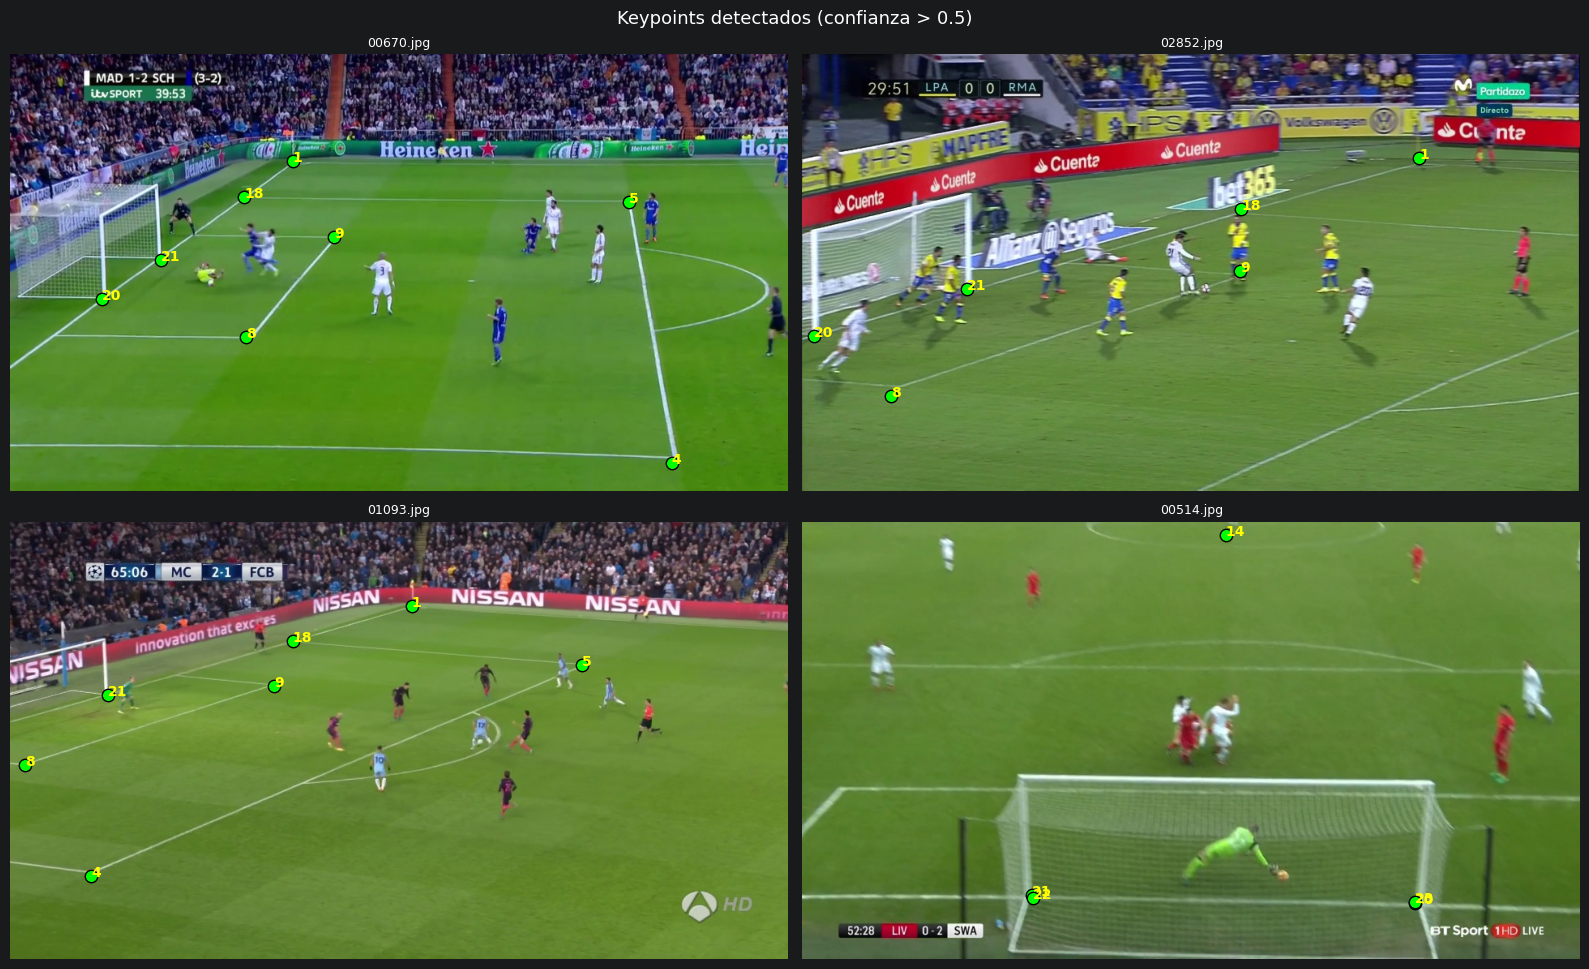

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import cv2
import random
from pathlib import Path
from ultralytics import YOLO

REPO_ROOT = Path("../..").resolve()
DATASET_DIR = REPO_ROOT / "data" / "soccernet_yolo"
model = YOLO(str(REPO_ROOT / "models" / "keypoints_base.pt"))

test_imgs = list((DATASET_DIR / "test" / "images").glob("*.jpg"))
muestras = random.sample(test_imgs, 4)

CONF_MIN = 0.5  # solo keypoints con confianza alta

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, img_path in zip(axes.flat, muestras):
    res = model(str(img_path), verbose=False)
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

    if res[0].keypoints is not None:
        kps_xy = res[0].keypoints.xy[0].cpu().numpy()
        kps_conf = res[0].keypoints.conf[0].cpu().numpy()  # confianza por keypoint

        for i, ((x, y), c) in enumerate(zip(kps_xy, kps_conf)):
            if c > CONF_MIN and x > 0 and y > 0:
                ax.scatter(x, y, c="lime", s=80, edgecolors="black", zorder=3)
                ax.annotate(str(i), (x, y), color="yellow", fontsize=10, fontweight="bold")

    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.suptitle(f"Keypoints detectados (confianza > {CONF_MIN})", fontsize=13)
plt.tight_layout()

output_fig = REPO_ROOT / "outputs" / "keypoints_test_filtrado.png"
output_fig.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()

In [6]:
import shutil

source = Path(results.save_dir) / "weights" / "best.pt"
destination = REPO_ROOT / "models" / "keypoints_base.pt"

shutil.copy2(source, destination)
print(f"Modelo guardado en: {destination}")
print(f"Tamaño: {destination.stat().st_size / (1024*1024):.2f} MB")

Modelo guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\keypoints_base.pt
Tamaño: 22.88 MB


## 7. Conclusiones

Tras este notebook:

- Se ha entrenado el modelo base de detección de keypoints del campo con el dataset SoccerNet-Calibration.
- El modelo queda guardado como `models/keypoints_base.pt`.
- Este modelo detecta los keypoints en cualquier estadio profesional gracias a la variedad de SoccerNet, y servirá de base para el fine-tuning con frames propios de la Bundesliga.
- Con los keypoints detectados se podrá calcular la homografía en la siguiente fase.